# 20 MW Batarya — İzdemir Aliağa: Python analizi
Bu defter, sunumdaki bütün rakamları gerçek EPİAŞ saatlik fiyatlarıyla yeniden hesaplar.
**Hücreleri yukarıdan aşağı sırayla çalıştır** (Jupyter: `Shift + Enter`). Hiçbir parametre girmen gerekmiyor;
veriyi kendisi indirir. Varsayımları değiştirmek için 1. hücredeki `V` sözlüğünü düzenle.

In [1]:
# 0) KURULUM — sadece ilk seferde gerekli (Jupyter'de çalışır)
%pip install -q pandas numpy highspy openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 1) KÜTÜPHANELER VE VARSAYIMLAR
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import highspy

# Veri: EPİAŞ'tan indirdiğin CSV'nin yolunu yaz ya da bu hazır adresi bırak (internet gerekir)
VERI = "https://raw.githubusercontent.com/oskkee/epias-ptf-data/main/Piyasa_Takas_Fiyati-25042025-25042026.csv"

V = {
    "santral_max_mw": 350, "santral_min_mw": 250, "santral_mc": 1500, "baglanti_limit_mw": 370,
    "pfk_fiyat": 1879,      # primer, TL/MW-saat (zayıf kaynak, TEİAŞ serisiyle değiştir)
    "sfk_fiyat": 2000,      # sekonder, TL/MW-saat
    "kullanilabilirlik": 6500 / 8760, "alsat_yakalama": 0.85,
    "kur": 50.0, "enerji_usd_kwh": 95, "guc_usd_kw": 170, "verim": 0.88, "cevrim_omru": 6000,
    "bakim_orani": 0.04, "sistem_gideri_mtl": 5.0,
    "sfk_blok_saat": 4, "pfk_enerji_orani": 1.25, "sfk_guvenlik": 1.125, "hedef_geri_odeme": 5.0,
}
MAVI, TURUNCU, GRI = "#2A6FDB", "#D9822B", "#8A94A6"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print("Hazır.")

Hazır.


In [3]:
# 2) VERİYİ OKU (EPİAŞ biçimi: Tarih;Saat;PTF (TL/MWh);...  sayılar 2.950,00 şeklinde)
df = pd.read_csv(VERI, sep=";", dtype=str)
zaman = pd.to_datetime(df["Tarih"] + " " + df["Saat"], format="%d.%m.%Y %H:%M")
fiyat = df["PTF (TL/MWh)"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False).astype(float)
ptf = pd.Series(fiyat.values, index=zaman).sort_index()
ptf = ptf[~ptf.index.duplicated()]["2025-04-25":"2026-04-24"]
print(f"{len(ptf):,} saat: {ptf.index.min():%d.%m.%Y} – {ptf.index.max():%d.%m.%Y}")
print(f"Ortalama PTF: {ptf.mean():,.0f} TL/MWh | en düşük {ptf.min():,.0f} | en yüksek {ptf.max():,.0f}")
print(f"PTF < 1.500 olan saat: {(ptf < 1500).sum():,}")
print(f"Doğrulama — Temmuz 2025 ortalaması: {ptf['2025-07'].mean():,.2f} (Montel'in yayınladığı: 2.965,16)")

8,760 saat: 25.04.2025 – 24.04.2026
Ortalama PTF: 2,471 TL/MWh | en düşük 0 | en yüksek 4,500
PTF < 1.500 olan saat: 1,674
Doğrulama — Temmuz 2025 ortalaması: 2,965.16 (Montel'in yayınladığı: 2.965,16)


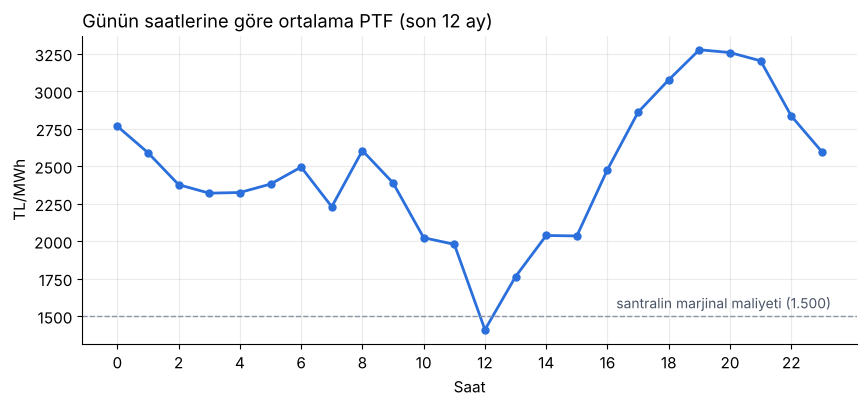

In [4]:
# 3) FİYAT PROFİLİ — günün hangi saati ucuz, hangisi pahalı?
saatlik = ptf.groupby(ptf.index.hour).mean()
fig, ax = plt.subplots()
ax.plot(saatlik.index, saatlik.values, color=MAVI, lw=2, marker="o", ms=5)
ax.axhline(1500, color=GRI, lw=1, ls="--")
ax.text(23.3, 1530, "santralin marjinal maliyeti (1.500)", ha="right", va="bottom", color="#4A5568", fontsize=10)
ax.set_title("Günün saatlerine göre ortalama PTF (son 12 ay)", loc="left")
ax.set_xlabel("Saat"); ax.set_ylabel("TL/MWh"); ax.set_xticks(range(0, 24, 2))
plt.show()

            ortalama_PTF  gunluk_spread_ort
2025-04-01        2003.0             2746.0
2025-05-01        2458.0             2441.0
2025-06-01        2202.0             2468.0
2025-07-01        2965.0             1370.0
2025-08-01        2939.0             1495.0
2025-09-01        2729.0             1950.0
2025-10-01        2740.0             2177.0
2025-11-01        2784.0             1875.0
2025-12-01        2973.0             1279.0
2026-01-01        2895.0             1419.0
2026-02-01        2078.0             2233.0
2026-03-01        1620.0             2407.0
2026-04-01         993.0             3332.0


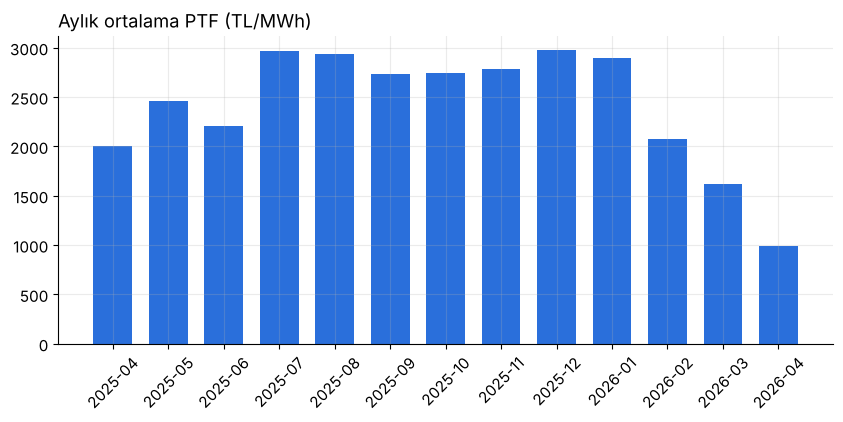

In [5]:
# 4) AYLIK FİYAT VE GÜNLÜK SPREAD
gunluk_spread = ptf.groupby(ptf.index.date).apply(lambda x: x.nlargest(2).mean() - x.nsmallest(2).mean())
gunluk_spread.index = pd.to_datetime(gunluk_spread.index)
aylik = pd.DataFrame({"ortalama_PTF": ptf.resample("MS").mean(),
                      "gunluk_spread_ort": gunluk_spread.resample("MS").mean()}).round(0)
display(aylik) if "display" in globals() else print(aylik)
fig, ax = plt.subplots()
ax.bar(aylik.index.strftime("%Y-%m"), aylik["ortalama_PTF"], color=MAVI, width=0.7)
ax.set_title("Aylık ortalama PTF (TL/MWh)", loc="left"); ax.tick_params(axis="x", rotation=45)
plt.show()

In [6]:
# 5) OPTİMİZASYON MODELİ — santral + batarya, her saat için en kârlı karar
def coz(p, v, batarya_mw, batarya_mwh, santral_sfk=True, pfk_pazar_max=None, **degisiklik):
    v = {**v, **degisiklik}
    T = v["sfk_blok_saat"]; B = len(p) // T; p = np.asarray(p[:B * T], float); n = len(p)
    Pb, E = float(batarya_mw), float(batarya_mwh)
    eta = v["verim"] ** 0.5
    asinma = v["enerji_usd_kwh"] * 1000 * v["kur"] / v["cevrim_omru"]
    pfk_pay, sfk_pay, av = v["pfk_enerji_orani"] / 2, v["sfk_guvenlik"] * T, v["kullanilabilirlik"]
    ig, ic, id_, is_, irp, irs, isp = 0, n, 2 * n, 3 * n, 4 * n, 5 * n, 5 * n + B
    nv = 5 * n + 2 * B
    alt, ust, kar = np.zeros(nv), np.zeros(nv), np.zeros(nv)
    alt[ig:ic], ust[ig:ic], kar[ig:ic] = v["santral_min_mw"], v["santral_max_mw"], p - v["santral_mc"]
    ust[ic:id_], kar[ic:id_] = Pb, -v["alsat_yakalama"] * p
    ust[id_:is_], kar[id_:is_] = Pb, v["alsat_yakalama"] * p - asinma
    ust[is_:irp] = E
    ust[irp:irs], kar[irp:irs] = min(Pb, Pb if pfk_pazar_max is None else pfk_pazar_max), v["pfk_fiyat"] * av
    ust[irs:isp], kar[irs:isp] = Pb, T * v["sfk_fiyat"] * av
    ust[isp:] = (v["santral_max_mw"] - v["santral_min_mw"]) / 2 if santral_sfk else 0
    kar[isp:] = T * v["sfk_fiyat"] * av
    h = highspy.Highs(); h.setOptionValue("output_flag", False); inf = highspy.kHighsInf
    h.addVars(nv, alt, ust); h.changeColsCost(nv, np.arange(nv, dtype=np.int32), kar)
    h.changeObjectiveSense(highspy.ObjSense.kMaximize)
    lo, hi, bas, sut, kat = [], [], [], [], []
    def k(a, b, kol, ks):
        bas.append(len(sut)); sut.extend(kol); kat.extend(ks); lo.append(a); hi.append(b)
    for t in range(n):
        b = t // T
        if t == 0: k(E / 2, E / 2, [is_, ic, id_], [1, -eta, 1 / eta])
        else: k(0, 0, [is_ + t, is_ + t - 1, ic + t, id_ + t], [1, -1, -eta, 1 / eta])
        k(-inf, v["santral_max_mw"], [ig + t, isp + b], [1, 1])
        k(v["santral_min_mw"], inf, [ig + t, isp + b], [1, -1])
        k(-inf, v["baglanti_limit_mw"], [ig + t, isp + b, id_ + t, irp + t, irs + b], [1, 1, 1, 1, 1])
        k(-inf, Pb, [id_ + t, irp + t, irs + b], [1, 1, 1]); k(-inf, Pb, [ic + t, irp + t, irs + b], [1, 1, 1])
        k(0, inf, [is_ + t, irp + t, irs + b], [1, -pfk_pay, -sfk_pay]); k(-inf, E, [is_ + t, irp + t, irs + b], [1, pfk_pay, sfk_pay])
    k(E / 2, E / 2, [is_ + n - 1], [1])
    h.addRows(len(lo), np.array(lo), np.array(hi), len(sut), np.array(bas, dtype=np.int32), np.array(sut, dtype=np.int32), np.array(kat))
    h.run()
    x = np.array(h.getSolution().col_value)
    g, c, d, rp, rs, sp = x[ig:ic], x[ic:id_], x[id_:is_], x[irp:irs], x[irs:isp], x[isp:]
    ref = np.sum((p - v["santral_mc"]) * np.where(p > v["santral_mc"], v["santral_max_mw"], v["santral_min_mw"]))
    yatirim = (E * 1000 * v["enerji_usd_kwh"] + Pb * 1000 * v["guc_usd_kw"]) * v["kur"] / 1e6
    gider = yatirim * v["bakim_orani"] + (v["sistem_gideri_mtl"] if Pb > 0 else 0)
    return {"yatirim": yatirim, "primer": rp.sum() * v["pfk_fiyat"] * av / 1e6,
            "batarya_sekonder": rs.sum() * T * v["sfk_fiyat"] * av / 1e6,
            "santral_sekonder": sp.sum() * T * v["sfk_fiyat"] * av / 1e6,
            "santral_enerji_kaybi": (np.sum((p - v["santral_mc"]) * g) - ref) / 1e6,
            "alsat": (v["alsat_yakalama"] * np.dot(p, d - c) - asinma * d.sum()) / 1e6,
            "gider": gider, "portfoy_net": (h.getInfo().objective_function_value - ref) / 1e6 - gider}

p = ptf.values
ref = coz(p, V, 0, 0)
print(f"Bataryasız (yalnız santral sekonderi): net {ref['portfoy_net']:.1f} M TL/yıl "
      f"= sekonder {ref['santral_sekonder']:.1f} − kaybedilen satış {-ref['santral_enerji_kaybi']:.1f}")

Bataryasız (yalnız santral sekonderi): net 129.0 M TL/yıl = sekonder 382.0 − kaybedilen satış 252.9


In [7]:
# 6) SENARYOLAR — bataryanın katkısı = senaryo neti − bataryasız neti
ref_sfk_ucuz = coz(p, V, 0, 0, sfk_fiyat=1112)
S = [("Önerilen 20/40", dict(batarya_mw=20, batarya_mwh=40), ref),
     ("Ucuz enerji 20/25", dict(batarya_mw=20, batarya_mwh=25), ref),
     ("Güvenli pay 20/30", dict(batarya_mw=20, batarya_mwh=30), ref),
     ("Büyük 40/50", dict(batarya_mw=40, batarya_mwh=50), ref),
     ("100/200, primer pazarı 20 MW", dict(batarya_mw=100, batarya_mwh=200, pfk_pazar_max=20), ref),
     ("Primer pazarı 10 MW", dict(batarya_mw=20, batarya_mwh=40, pfk_pazar_max=10), ref),
     ("Primer 669", dict(batarya_mw=20, batarya_mwh=40, pfk_fiyat=669), ref),
     ("Sekonder 1.112", dict(batarya_mw=20, batarya_mwh=40, sfk_fiyat=1112), ref_sfk_ucuz),
     ("Primer 669 + sekonder 1.112", dict(batarya_mw=20, batarya_mwh=40, pfk_fiyat=669, sfk_fiyat=1112), ref_sfk_ucuz),
     ("Kur 62", dict(batarya_mw=20, batarya_mwh=40, kur=62), ref)]
satir = []
for ad, kw, r0 in S:
    r = coz(p, V, **kw); katki = r["portfoy_net"] - r0["portfoy_net"]
    satir.append({"senaryo": ad, **{k: round(x, 1) for k, x in r.items()},
                  "batarya_katkisi": round(katki, 1), "geri_odeme_yil": round(r["yatirim"] / katki, 2)})
tablo = pd.DataFrame(satir).set_index("senaryo")
display(tablo) if "display" in globals() else print(tablo.to_string())

                              yatirim  primer  batarya_sekonder  santral_sekonder  santral_enerji_kaybi  alsat  gider  portfoy_net  batarya_katkisi  geri_odeme_yil
senaryo                                                                                                                                                            
Önerilen 20/40                  360.0   220.6              25.2             382.0                -252.9    0.0   19.4        355.4            226.4            1.59
Ucuz enerji 20/25               288.8   244.3               0.0             382.0                -252.9    0.0   16.6        356.8            227.7            1.27
Güvenli pay 20/30               312.5   236.4               8.4             382.0                -252.9    0.0   17.5        356.3            227.3            1.37
Büyük 40/50                     577.5   348.9              13.6             307.8                -244.7    0.0   28.1        397.5            268.5            2.15
100/200, primer 

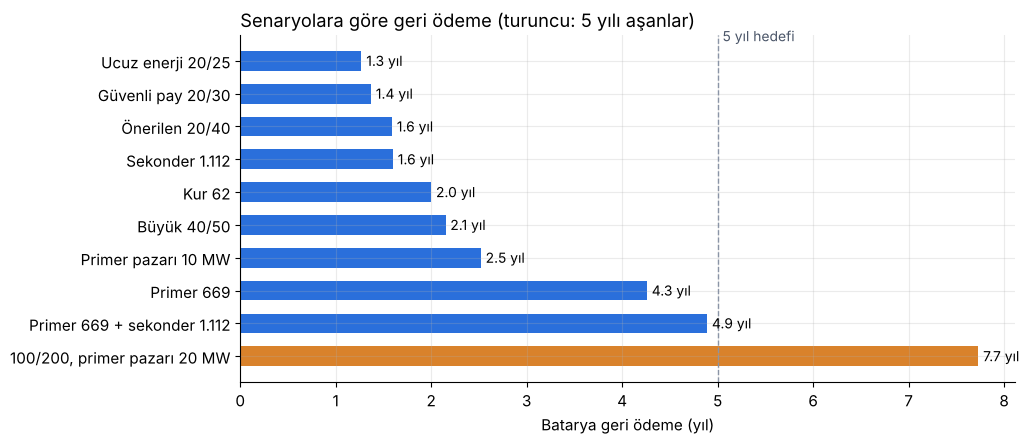

In [8]:
# 7) GRAFİK — senaryoların geri ödemesi
t = tablo["geri_odeme_yil"].sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(t.index, t.values, color=[MAVI if x <= V["hedef_geri_odeme"] else TURUNCU for x in t.values], height=0.6)
ax.axvline(V["hedef_geri_odeme"], color=GRI, lw=1, ls="--")
ax.text(V["hedef_geri_odeme"] + 0.05, -0.6, "5 yıl hedefi", color="#4A5568", fontsize=10)
for i, x in enumerate(t.values):
    ax.text(x + 0.05, i, f"{x:.1f} yıl", va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlabel("Batarya geri ödeme (yıl)")
ax.set_title("Senaryolara göre geri ödeme (turuncu: 5 yılı aşanlar)", loc="left")
plt.show()

300     8.57
400     6.77
500     5.56
540     5.19
600     4.71
669     4.26
800     3.61
1000    2.92
1500    1.98
1879    1.59
2500    1.18
3000    0.97

5 yıl için gereken primer fiyatı ≈ 563 TL/MW-saat


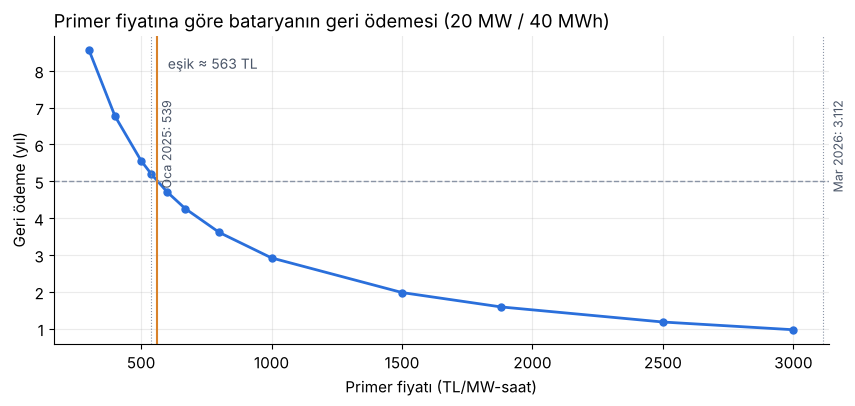

In [9]:
# 8) PRİMER FİYATI DEĞİŞİRSE — eşik nerede?
fiyatlar = [300, 400, 500, 540, 600, 669, 800, 1000, 1500, 1879, 2500, 3000]
gp = []
for f in fiyatlar:
    r = coz(p, V, 20, 40, pfk_fiyat=f); katki = r["portfoy_net"] - ref["portfoy_net"]
    gp.append(r["yatirim"] / katki)
egri = pd.Series(gp, index=fiyatlar, name="geri_odeme_yil").round(2)
# 5 yıl eşiğini ikiye bölme ile bul
lo_, hi_ = 300, 1000
for _ in range(12):
    m = (lo_ + hi_) / 2; r = coz(p, V, 20, 40, pfk_fiyat=m)
    (lo_, hi_) = (m, hi_) if r["yatirim"] / (r["portfoy_net"] - ref["portfoy_net"]) > V["hedef_geri_odeme"] else (lo_, m)
esik = (lo_ + hi_) / 2
print(egri.to_string()); print(f"\n5 yıl için gereken primer fiyatı ≈ {esik:,.0f} TL/MW-saat")

fig, ax = plt.subplots()
ax.plot(egri.index, egri.values, color=MAVI, lw=2, marker="o", ms=5)
ax.axhline(V["hedef_geri_odeme"], color=GRI, lw=1, ls="--")
ax.axvline(esik, color=TURUNCU, lw=1.5)
ax.text(esik + 40, ax.get_ylim()[1] * 0.9, f"eşik ≈ {esik:,.0f} TL", color="#4A5568", fontsize=10)
for x, ad in [(539, "Oca 2025: 539"), (3112, "Mar 2026: 3.112")]:
    ax.axvline(x, color=GRI, lw=0.8, ls=":"); ax.text(x + 30, 7.2, ad, fontsize=9, color="#4A5568", rotation=90, va="top")
ax.set_xlabel("Primer fiyatı (TL/MW-saat)"); ax.set_ylabel("Geri ödeme (yıl)")
ax.set_title("Primer fiyatına göre bataryanın geri ödemesi (20 MW / 40 MWh)", loc="left")
plt.show()

In [10]:
# 9) SONUÇLARI EXCEL'E KAYDET
with pd.ExcelWriter("bess_sonuclar.xlsx") as w:
    tablo.to_excel(w, sheet_name="Senaryolar"); egri.to_frame().to_excel(w, sheet_name="Primer_esik")
    aylik.to_excel(w, sheet_name="Aylik_fiyat"); pd.Series(V).to_frame("deger").to_excel(w, sheet_name="Varsayimlar")
print("Kaydedildi: bess_sonuclar.xlsx")

Kaydedildi: bess_sonuclar.xlsx
